# 04 — Backtest 001.2: saída por Chandelier (trailing stop por ATR) · H4, H1 e M15

**LHS Quant Lab** · notebook didático · foco em day trading

## De onde viemos
| Backtest | O que testou | Resultado |
|---|---|---|
| **001** | SMA 20×50, sempre posicionado, sai só no cruzamento contrário (EURUSD H4) | ❌ −20%, Sharpe −0,12 |
| **001.1** | + walk-forward das médias + filtro de ML (logística) | 🟡 filtro promissor, poucos trades |
| **001.2** (este) | mesma entrada, nova **saída**: Chandelier, em **H4, H1 e M15** | ver conclusões |

## Por que mexer na saída?
Na regra original a saída é o **cruzamento contrário**, que chega atrasado: quando a SMA 20 finalmente cruza
de volta, o preço já devolveu boa parte do lucro. E em mercado lateral a perda corre solta até o próximo cruzamento.

## O Chandelier Exit
Criado por Chuck LeBeau, é o trailing stop clássico de *trend following*:

- **Comprado:** stop = **maior máxima desde a entrada − K × ATR**. O stop só **sobe**, nunca desce.
- **Vendido:** stop = **menor mínima desde a entrada + K × ATR**. O stop só **desce**.
- O **ATR** (Average True Range, 14 barras) mede quanto o par anda por barra. Com `K = 3`, o stop fica a
  "3 barras normais" de distância: longe o bastante para não sair no ruído, perto o bastante para travar o lucro.

A operação termina no que acontecer **primeiro**: stop tocado, cruzamento contrário ou fim do dia (no intraday).
Depois de sair, ficamos **fora até o próximo cruzamento**.

## Day trade: H1 e M15
No H1 e no M15 aplicamos as regras de day trade da LHS:
- **Janela de entrada:** só entra se a barra do sinal fechar entre **9h e 21h do servidor** (Londres + Nova York, spread baixo).
- **Zerar no fim do dia:** toda posição é fechada no fechamento da barra que termina às **23h do servidor** (e na última barra
  do dia/semana). Não dorme posicionado, não paga swap, não pega gap de fim de semana.
- O H4 fica **sem** essas regras (6 barras por dia), para comparar direto com o 001 e o 001.1.

## Roteiro
1. Configuração
2. O motor com stop (e como evitar look-ahead com stop dentro da barra)
3. Conferência: reproduzir o Backtest 001
4. O Chandelier na prática (gráfico de uma operação)
5. O pipeline de cada timeframe: walk-forward do K + filtro de ML
6. Resultados H4
7. Resultados H1
8. Resultados M15
9. Resumo entre timeframes
10. Filtro de ML × filtros aleatórios
11. Salvar
12. Conclusões e exercícios

## 1. Configuração
- `CONFIG_TF`: para cada timeframe, a janela de day trade (`sessao`, `hora_zerar`) e as janelas do walk-forward.
  O M15 só tem dados desde **out/2022** (limite de ~100 mil barras do MT5), então usa treino de 12 meses e teste de 3 meses.
- `GRADE_K`: candidatos para o multiplicador do ATR. `K_FIXO = 3` é a referência "de livro", sem otimização.
- Custos, ML e seed iguais ao 001.1.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ---------------- parâmetros do teste ----------------
BACKTEST_ID = "001.2"
SIMBOLO = "EURUSD"
TIMEFRAMES = ["H4", "H1", "M15"]
MEDIA_RAPIDA, MEDIA_LENTA = 20, 50

SLIPPAGE_PONTOS = 2  # por lado
COMISSAO_PCT = 0.0  # XM Standard = 0
CAPITAL_INICIAL = 10_000
DATA_INICIO = "2010-01-01"

# saída Chandelier
ATR_PERIODO = 14
GRADE_K = [2.0, 2.5, 3.0, 4.0, 5.0]
K_FIXO = 3.0
MIN_TRADES_TREINO = 30

CONFIG_TF = {
    "H4": {"minutos": 240, "sessao": None, "hora_zerar": None,
           "inicio_oos": "2014-01-01", "treino_meses": 48, "teste_meses": 12},
    "H1": {"minutos": 60, "sessao": (9, 21), "hora_zerar": 23,
           "inicio_oos": "2015-01-01", "treino_meses": 48, "teste_meses": 12},
    "M15": {"minutos": 15, "sessao": (9, 21), "hora_zerar": 23,
            "inicio_oos": "2023-11-01", "treino_meses": 12, "teste_meses": 3},
}

# machine learning (igual ao 001.1)
PROB_MINIMA = 0.50
MIN_TRADES_ML = 100
N_SIM = 300
SEED = 42

RAIZ = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dados" / "xm").is_dir()), None)
if RAIZ is None:
    raise FileNotFoundError(f"Não encontrei a pasta dados/xm a partir de {Path.cwd()}")
PASTA_DADOS = RAIZ / "dados" / "xm"
sys.path.insert(0, str(RAIZ / "src"))
from lhsquant.estilo import aplicar_estilo, CORES

aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
info = pd.read_parquet(PASTA_DADOS / "info_simbolos.parquet")
PONTO = float(info.loc[info["simbolo"] == SIMBOLO, "ponto"].iloc[-1])

## 2. O motor com stop
Com stop móvel, o resultado de cada barra depende do que aconteceu antes (o nível do stop "lembra" a maior máxima
desde a entrada). Isso não dá para fazer só com operações de coluna do pandas, então o motor é um **laço barra a barra**
compilado com **numba** (fica quase tão rápido quanto C, roda as 100 mil barras do M15 em milissegundos).

### Regras de execução (sem look-ahead)
Em cada barra *t*, nesta ordem:
1. **Durante a barra:** se estamos posicionados, o stop em vigor foi calculado **no fechamento da barra anterior**.
   Usamos a máxima e a mínima da barra *t* só para saber **se o preço tocou** esse nível, e isso é legítimo
   (uma ordem stop pendurada no MT5 faria exatamente isso).
   - Saída no preço do stop; se a barra **abriu além do stop** (gap), saída na abertura, que é pior.
2. **No fechamento da barra:** atualiza o stop com a máxima/mínima e o ATR da barra *t*, que só valem a partir de *t+1*.
3. **Decisões no fechamento:** cruzamento contrário → sai; fim do dia → sai; cruzamento novo dentro da janela → entra
   (o resultado começa a contar na barra *t+1*, como no 001).

**Custo:** a operação completa (spread da barra + 2 × slippage) é cobrada na entrada, igual ao 001.

`k` é uma **série** (um valor por barra). Assim o walk-forward pode trocar o K a cada janela numa única simulação,
com os custos e as posições sempre coerentes. Com `k = 0` não há stop: é a regra original.

In [2]:
@njit(cache=True)
def motor(o, h, l, c, atr, sinal, pode_entrar, zerar, k, custo):
    n = len(c)
    ret = np.zeros(n)
    cst = np.zeros(n)
    tid = np.full(n, -1, np.int64)  # id da operação em andamento em cada barra
    nivel = np.full(n, np.nan)  # nível do stop (para gráfico)
    ent = np.zeros(n, np.int64)
    sai = np.zeros(n, np.int64)
    dire = np.zeros(n, np.int64)
    mot = np.zeros(n, np.int64)  # 0 cruzamento, 1 stop, 2 fim do dia, 3 fim dos dados
    nt, pos, atual, stop = 0, 0, -1, np.nan
    for t in range(1, n):
        # 1) durante a barra t
        if pos != 0:
            tid[t] = atual
            px, saiu = c[t], False
            if not np.isnan(stop):
                if pos == 1 and l[t] <= stop:
                    px, saiu = min(o[t], stop), True
                elif pos == -1 and h[t] >= stop:
                    px, saiu = max(o[t], stop), True
            ret[t] = pos * (px / c[t - 1] - 1)
            if saiu:
                sai[atual], mot[atual], pos = t, 1, 0
            elif k[t] > 0:  # 2) atualiza o stop no fechamento (vale a partir de t+1)
                if pos == 1:
                    stop = max(stop, h[t] - k[t] * atr[t])
                else:
                    stop = min(stop, l[t] + k[t] * atr[t])
                nivel[t] = stop
        # 3) decisões no fechamento da barra t
        cruzou = sinal[t] != 0 and sinal[t] != sinal[t - 1]
        if pos != 0 and cruzou and sinal[t] != pos:
            sai[atual], mot[atual], pos = t, 0, 0
        if pos != 0 and zerar[t]:
            sai[atual], mot[atual], pos = t, 2, 0
        if pos == 0 and cruzou and pode_entrar[t] and not zerar[t] and t + 1 < n:
            pos, atual = sinal[t], nt
            nt += 1
            ent[atual], dire[atual] = t + 1, pos
            cst[t + 1] += custo[t]
            stop = c[t] - pos * k[t] * atr[t] if k[t] > 0 else np.nan
            nivel[t] = stop
    if pos != 0:
        sai[atual], mot[atual] = n - 1, 3
    return ret - cst, cst, tid, nivel, ent[:nt], sai[:nt], dire[:nt], mot[:nt]

### Preparação de cada timeframe e funções auxiliares
- `preparar(tf)`: carrega os dados, calcula o sinal 20×50 na barra fechada, ATR, custos, janela de entrada,
  barras de "zerar" e as features do ML (as mesmas do 001.1).
- `rodar(p, k)`: roda o motor e devolve retornos, custos e a lista de operações (com o **motivo** da saída).
- `filtrar(res, ids)`: mantém só as operações escolhidas (ex.: as aceitas pelo ML) e zera o resto.
- `metricas(...)`: as métricas de sempre, agora com o **retorno sem custos** ao lado.

In [3]:
MOTIVOS = np.array(["cruzamento", "stop", "fim do dia", "fim dos dados"])
DIRECIONAIS = ["incl_lenta", "momento_20", "dist_sma200"]


def preparar(tf):
    cfg = CONFIG_TF[tf]
    df = pd.read_parquet(PASTA_DADOS / SIMBOLO / f"{tf}.parquet").sort_index().loc[DATA_INICIO:]
    alta, baixa, fech = df["maxima"], df["minima"], df["fechamento"]
    mr, ml = fech.rolling(MEDIA_RAPIDA).mean(), fech.rolling(MEDIA_LENTA).mean()
    sinal = pd.Series(np.where(mr > ml, 1, -1), index=df.index).where(ml.notna(), 0)

    tr = pd.concat([alta - baixa, (alta - fech.shift()).abs(), (baixa - fech.shift()).abs()], axis=1).max(axis=1)
    atr = tr.ewm(alpha=1 / ATR_PERIODO, adjust=False).mean()
    custo = (df["spread"] + 2 * SLIPPAGE_PONTOS) * PONTO / fech + COMISSAO_PCT / 100

    fecha = df.index + pd.Timedelta(minutes=cfg["minutos"])  # horário de fechamento da barra
    if cfg["sessao"]:
        pode = (fecha.hour >= cfg["sessao"][0]) & (fecha.hour < cfg["sessao"][1])
        dia = df.index.normalize()
        ultimo_do_dia = np.append(dia[1:] != dia[:-1], True)
        zerar = (fecha.hour >= cfg["hora_zerar"]) | ultimo_do_dia
    else:
        pode, zerar = np.ones(len(df), bool), np.zeros(len(df), bool)

    # features do ML (iguais ao 001.1), na barra do sinal
    sobe, desce = alta.diff(), -baixa.diff()
    dmp = pd.Series(np.where((sobe > desce) & (sobe > 0), sobe, 0.0), index=df.index)
    dmm = pd.Series(np.where((desce > sobe) & (desce > 0), desce, 0.0), index=df.index)
    dip = 100 * dmp.ewm(alpha=1 / 14, adjust=False).mean() / atr
    dim = 100 * dmm.ewm(alpha=1 / 14, adjust=False).mean() / atr
    adx = (100 * (dip - dim).abs() / (dip + dim)).ewm(alpha=1 / 14, adjust=False).mean()
    sma200 = fech.rolling(200).mean()
    feat = pd.DataFrame(
        {
            "adx": adx,
            "atr_pct": atr / fech * 100,
            "regime_vol": atr / tr.rolling(100).mean(),
            "incl_lenta": (ml - ml.shift(10)) / atr,
            "momento_20": (fech - fech.shift(20)) / atr,
            "dist_sma200": (fech - sma200) / atr,
            "cruzamentos_50": (sinal != sinal.shift(1)).astype(int).rolling(50).sum(),
        }
    )
    return {
        "tf": tf, "cfg": cfg, "df": df, "idx": df.index, "feat": feat,
        "barras_ano": len(df) / ((df.index[-1] - df.index[0]).days / 365.25),
        "ret_mercado": fech.pct_change().fillna(0),
        "arr": (df["abertura"].to_numpy(float), alta.to_numpy(float), baixa.to_numpy(float), fech.to_numpy(float),
                atr.to_numpy(float), sinal.to_numpy(np.int64), np.asarray(pode, bool), np.asarray(zerar, bool)),
        "custo": custo.to_numpy(float),
    }


def rodar(p, k):
    n = len(p["idx"])
    k_arr = np.full(n, float(k)) if np.isscalar(k) else np.asarray(k, float)
    r, cst, tid, nivel, ent, sai, dire, mot = motor(*p["arr"], k_arr, p["custo"])
    ok = tid >= 0
    resultado = np.expm1(np.bincount(tid[ok], weights=np.log1p(r[ok]), minlength=len(ent)))
    trades = pd.DataFrame(
        {
            "entrada": p["idx"][ent], "saida": p["idx"][sai], "direcao": dire, "barras": sai - ent + 1,
            "motivo": MOTIVOS[mot], "resultado": resultado, "i_entrada": ent,
        }
    )
    return {"ret": pd.Series(r, p["idx"]), "custo": pd.Series(cst, p["idx"]), "tid": tid, "nivel": nivel, "trades": trades}


def filtrar(res, ids):
    manter = np.isin(res["tid"], np.asarray(ids))
    ret = res["ret"].where(manter, 0.0)
    bruto = (res["ret"] + res["custo"]).where(manter, 0.0)
    return ret, bruto, res["trades"].iloc[np.asarray(ids)]


def drawdown(cap):
    return cap / cap.cummax() - 1


def sharpe(ret, ba):
    return ret.mean() / ret.std() * np.sqrt(ba) if len(ret) and ret.std() > 0 else np.nan


def metricas(ret, ba, trades_=None, bruto=None):
    trades_ = pd.DataFrame({"resultado": []}) if trades_ is None else trades_
    cap = (1 + ret).cumprod()
    anos = len(ret) / ba
    ganhos = trades_.loc[trades_["resultado"] > 0, "resultado"]
    perdas = trades_.loc[trades_["resultado"] <= 0, "resultado"]
    neg = ret[ret < 0]
    return pd.Series(
        {
            "Retorno total %": (cap.iloc[-1] - 1) * 100,
            "Retorno sem custos %": ((1 + bruto).prod() - 1) * 100 if bruto is not None else np.nan,
            "CAGR %": (cap.iloc[-1] ** (1 / anos) - 1) * 100,
            "Nº trades": len(trades_) or np.nan,
            "Win rate %": len(ganhos) / len(trades_) * 100 if len(trades_) else np.nan,
            "Payoff": ganhos.mean() / abs(perdas.mean()) if len(perdas) else np.nan,
            "Expectativa %/trade": trades_["resultado"].mean() * 100,
            "Fator de lucro": ganhos.sum() / abs(perdas.sum()) if len(perdas) else np.nan,
            "Máx. drawdown %": drawdown(cap).min() * 100,
            "Sharpe": sharpe(ret, ba),
            "Sortino": ret.mean() / np.sqrt((neg**2).sum() / len(ret)) * np.sqrt(ba),
        }
    )


PREP = {tf: preparar(tf) for tf in TIMEFRAMES}
for tf, p in PREP.items():
    print(f"{tf}: {len(p['idx']):,} barras de {p['idx'][0]:%Y-%m-%d} a {p['idx'][-1]:%Y-%m-%d} | "
          f"barras/ano {p['barras_ano']:,.0f} | entrada permitida em {p['arr'][6].mean():.0%} das barras")

H4: 26,119 barras de 2010-01-04 a 2026-10-16 | barras/ano 1,557 | entrada permitida em 100% das barras
H1: 100,017 barras de 2010-09-02 a 2026-10-16 | barras/ano 6,204 | entrada permitida em 50% das barras
M15: 100,072 barras de 2022-10-06 a 2026-10-16 | barras/ano 24,848 | entrada permitida em 50% das barras


## 3. Conferência: reproduzir o Backtest 001
Com `k = 0` (sem stop) e sem regras de day trade, o motor novo **tem** que dar o mesmo resultado do 001 no H4.
Se não der, há erro no motor.

In [4]:
r0 = rodar(PREP["H4"], 0.0)
_, b0, _ = filtrar(r0, np.arange(len(r0["trades"])))
m0 = metricas(r0["ret"], PREP["H4"]["barras_ano"], r0["trades"], b0)
print(f"Motor novo, k=0  -> retorno {m0['Retorno total %']:.1f}% | trades {m0['Nº trades']:.0f} | Sharpe {m0['Sharpe']:.2f}")
print("Backtest 001     -> retorno -20.2% | trades 586 | Sharpe -0.12")

Motor novo, k=0  -> retorno -20.2% | trades 586 | Sharpe -0.12
Backtest 001     -> retorno -20.2% | trades 586 | Sharpe -0.12


## 4. O Chandelier na prática
Uma operação recente do H4 com `K = 3`: a linha âmbar é o stop. Repare que ele só anda **a favor** da operação
e que a saída acontece quando o preço volta e toca a linha, muito antes do cruzamento contrário.

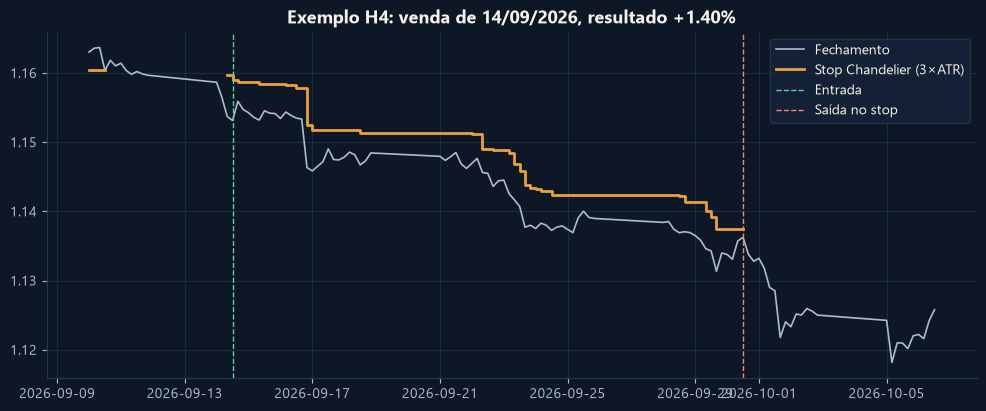

In [5]:
p = PREP["H4"]
r3 = rodar(p, K_FIXO)
t3 = r3["trades"]
exemplo = t3[(t3["motivo"] == "stop") & (t3["barras"] >= 20)].iloc[-1]
i0, i1 = int(exemplo["i_entrada"]) - 15, p["idx"].get_loc(exemplo["saida"]) + 25
janela = p["df"].iloc[i0:i1]
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(janela.index, janela["fechamento"], color=CORES["texto_suave"], lw=1.2, label="Fechamento")
ax.plot(janela.index, r3["nivel"][i0:i1], color=CORES["primaria"], lw=2, drawstyle="steps-post", label=f"Stop Chandelier ({K_FIXO:g}×ATR)")
ax.axvline(exemplo["entrada"], color=CORES["positivo"], ls="--", lw=1, label="Entrada")
ax.axvline(exemplo["saida"], color=CORES["negativo"], ls="--", lw=1, label="Saída no stop")
lado = "compra" if exemplo["direcao"] == 1 else "venda"
ax.set_title(f"Exemplo H4: {lado} de {exemplo['entrada']:%d/%m/%Y}, resultado {exemplo['resultado']:+.2%}")
ax.legend()
plt.show()

## 5. O pipeline de cada timeframe
Para cada timeframe, a função `analisar_tf()` faz:

1. **Saída original** (`k = 0`), com as regras de day trade no H1/M15: a referência.
2. **Chandelier fixo** com `K = 3`, sem otimização nenhuma.
3. **Chandelier walk-forward:** em cada janela de treino escolhe o K de maior Sharpe líquido (entre `GRADE_K`, com mínimo de
   operações) e usa esse K na janela seguinte. Tudo numa única simulação com o K variando no tempo.
4. **Chandelier WF + filtro de ML:** meta-labeling como no 001.1. A regressão logística é retreinada no início de cada janela
   de teste, só com operações já encerradas, e aceita a operação se a probabilidade de lucro for ≥ `PROB_MINIMA`.
   Como a entrada só acontece em cruzamento e cada operação termina antes da próxima entrada, pular uma operação
   não altera as outras: o filtro só escolhe um subconjunto.

Todas as versões são medidas **só fora da amostra** (a partir de `inicio_oos`), com as operações que **abrem** nesse período.

In [6]:
def janelas(p):
    cfg = p["cfg"]
    ini, lista = pd.Timestamp(cfg["inicio_oos"]), []
    while ini <= p["idx"][-1]:
        fim = ini + pd.DateOffset(months=cfg["teste_meses"])
        lista.append((ini - pd.DateOffset(months=cfg["treino_meses"]), ini, fim))
        ini = fim
    return lista


def analisar_tf(tf):
    p = PREP[tf]
    ba, idx, jan = p["barras_ano"], p["idx"], janelas(p)
    inicio_oos = jan[0][1]
    oos = idx >= inicio_oos

    # --- walk-forward do K ---
    res_k = {K: rodar(p, K) for K in GRADE_K}
    k_arr, linhas = np.zeros(len(idx)), []
    for tr_ini, te_ini, te_fim in jan:
        m_tr, m_te = (idx >= tr_ini) & (idx < te_ini), (idx >= te_ini) & (idx < te_fim)
        cand = {}
        for K, r in res_k.items():
            n_tr = r["trades"]["entrada"].between(tr_ini, te_ini, inclusive="left").sum()
            if n_tr >= MIN_TRADES_TREINO:
                cand[K] = sharpe(r["ret"][m_tr], ba)
        K = max(cand, key=cand.get) if cand else K_FIXO
        k_arr[m_te] = K
        linhas.append({"inicio_teste": te_ini.date(), "K": K, "sharpe_treino": cand.get(K, np.nan),
                       "sharpe_teste": sharpe(res_k[K]["ret"][m_te], ba)})
    k_arr[~oos] = linhas[0]["K"]  # antes do OOS: K da 1ª janela (só gera rótulos de treino para o ML)
    wf = pd.DataFrame(linhas)
    res_wf = rodar(p, k_arr)

    # --- meta-labeling sobre as operações do Chandelier WF ---
    ds = res_wf["trades"].copy()
    ds[list(p["feat"].columns)] = p["feat"].iloc[ds["i_entrada"] - 1].to_numpy()  # barra do sinal
    ds[DIRECIONAIS] = ds[DIRECIONAIS].mul(ds["direcao"], axis=0)
    ds["alvo"] = (ds["resultado"] > 0).astype(int)
    features = list(p["feat"].columns) + ["direcao"]
    ds["prob"] = np.nan
    for _, te_ini, te_fim in jan:
        treino = (ds["saida"] < te_ini) & ds[features].notna().all(axis=1)
        teste = ds["entrada"].between(te_ini, te_fim, inclusive="left")
        if treino.sum() >= MIN_TRADES_ML and teste.any():
            mod = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=1000))
            mod.fit(ds.loc[treino, features], ds.loc[treino, "alvo"])
            ds.loc[teste, "prob"] = mod.predict_proba(ds.loc[teste, features].fillna(0))[:, 1]
    ds_oos = ds[ds["entrada"] >= inicio_oos].copy()
    ds_oos["aceita"] = ds_oos["prob"] >= PROB_MINIMA

    # --- versões, todas fora da amostra ---
    def ids_oos(res):
        return np.flatnonzero(res["trades"]["entrada"] >= inicio_oos)

    res_orig, res_fixo = rodar(p, 0.0), res_k[K_FIXO]
    versoes = {
        "Saída original": (res_orig, ids_oos(res_orig)),
        f"Chandelier fixo {K_FIXO:g}×ATR": (res_fixo, ids_oos(res_fixo)),
        "Chandelier walk-forward": (res_wf, ids_oos(res_wf)),
        "Chandelier WF + ML": (res_wf, ds_oos.index[ds_oos["aceita"]].to_numpy()),
    }
    tabela = {"Buy & hold": metricas(p["ret_mercado"][oos], ba)}
    curvas = {"Buy & hold": CAPITAL_INICIAL * (1 + p["ret_mercado"][oos]).cumprod()}
    motivos = {}
    for nome, (res, ids) in versoes.items():
        ret, bruto, tr_ = filtrar(res, ids)
        tabela[nome] = metricas(ret[oos], ba, tr_, bruto[oos])
        curvas[nome] = CAPITAL_INICIAL * (1 + ret[oos]).cumprod()
        motivos[nome] = tr_["motivo"].value_counts(normalize=True) * 100

    # --- ML × filtros aleatórios (retorno total = produto dos resultados das operações aceitas) ---
    rng = np.random.default_rng(SEED)
    res_t = ds_oos["resultado"].to_numpy()
    sens = {}
    for lim in [0.40, 0.45, 0.50, 0.55]:
        aceita = (ds_oos["prob"] >= lim).to_numpy()
        k_ = int(aceita.sum())
        if k_ == 0:
            continue
        total = np.prod(1 + res_t[aceita]) - 1
        aleat = np.array([np.prod(1 + res_t[rng.choice(len(res_t), size=k_, replace=False)]) - 1 for _ in range(N_SIM)])
        sens[lim] = {"aceitas": k_, "retorno %": total * 100, "percentil": (aleat < total).mean() * 100}
    auc = roc_auc_score(ds_oos["alvo"], ds_oos["prob"]) if ds_oos["prob"].notna().all() else np.nan

    return {"wf": wf, "tabela": pd.DataFrame(tabela), "curvas": curvas, "motivos": pd.DataFrame(motivos).fillna(0),
            "ds_oos": ds_oos, "sens": pd.DataFrame(sens).T, "auc": auc, "inicio_oos": inicio_oos,
            "sharpe_por_k": {K: sharpe(r["ret"][oos], ba) for K, r in res_k.items()}}


def mostrar(tf, R):
    wf = R["wf"]
    print(f"{tf} | fora da amostra desde {R['inicio_oos']:%Y-%m-%d} | {len(wf)} janelas de teste")
    print(f"K escolhido por janela: {wf['K'].value_counts().sort_index().to_dict()}")
    print(f"Sharpe médio do K escolhido: treino {wf['sharpe_treino'].mean():.2f} | teste {wf['sharpe_teste'].mean():.2f}")
    print(f"ML: AUC {R['auc']:.3f} | aceitou {R['ds_oos']['aceita'].sum()} de {len(R['ds_oos'])} operações")
    print("\nComo as operações terminaram (% por motivo):")
    display(R["motivos"].round(1))
    display(R["tabela"].round(2))


RES = {}

## 6. Resultados H4
O H4 é a comparação direta com o 001 e o 001.1 (sem janela de day trade).

**Como ler:**
- **Saída original × Chandelier:** o stop melhorou o payoff, o drawdown e o Sharpe? Ou só trocou poucas perdas grandes por muitas pequenas?
- **Fixo × walk-forward:** se o K otimizado não bate o K = 3 "de livro", a otimização não está agregando.
- **Retorno sem custos:** o stop gera mais operações (sai e espera o próximo cruzamento), então os custos podem pesar mais.
- **Motivos de saída:** quantas operações terminaram no stop, no cruzamento ou no fim do dia.

In [7]:
RES["H4"] = analisar_tf("H4")
mostrar("H4", RES["H4"])

H4 | fora da amostra desde 2014-01-01 | 13 janelas de teste
K escolhido por janela: {2.0: 5, 2.5: 1, 3.0: 3, 4.0: 3, 5.0: 1}
Sharpe médio do K escolhido: treino 0.12 | teste -0.43
ML: AUC 0.528 | aceitou 87 de 461 operações

Como as operações terminaram (% por motivo):


,Saída original,Chandelier fixo 3×ATR,Chandelier walk-forward,Chandelier WF + ML
motivo,,,,
cruzamento,99.8000,9.1000,14.1000,6.9000
fim dos dados,0.2000,0.0000,0.0000,0.0000
stop,0.0000,90.9000,85.9000,93.1000


,Buy & hold,Saída original,Chandelier fixo 3×ATR,Chandelier walk-forward,Chandelier WF + ML
Retorno total %,-18.6300,-26.5700,-11.5200,-15.7400,3.1000
Retorno sem custos %,NaN,-20.4500,-4.1400,-8.7200,4.4600
CAGR %,-1.6000,-2.3900,-0.9500,-1.3300,0.2400
Nº trades,NaN,461.0000,461.0000,461.0000,87.0000
Win rate %,NaN,36.6600,37.3100,35.5700,40.2300
Payoff,NaN,1.4900,1.5400,1.5900,1.7100
Expectativa %/trade,NaN,-0.0600,-0.0200,-0.0300,0.0400
Fator de lucro,NaN,0.8600,0.9200,0.8800,1.1500
Máx. drawdown %,-31.5500,-34.5700,-23.5600,-27.7400,-6.5300
Sharpe,-0.1700,-0.2700,-0.1700,-0.2600,0.1300


## 7. Resultados H1 (day trade)
Aqui entram as regras de day trade: só entra entre 9h e 21h do servidor e zera às 23h. Uma média de 50 barras
no H1 cobre ~2 dias, então muitas operações vão terminar pelo **fim do dia**, antes do stop ou do cruzamento.

In [8]:
RES["H1"] = analisar_tf("H1")
mostrar("H1", RES["H1"])

H1 | fora da amostra desde 2015-01-01 | 12 janelas de teste
K escolhido por janela: {2.0: 1, 2.5: 3, 3.0: 3, 4.0: 3, 5.0: 2}
Sharpe médio do K escolhido: treino 0.03 | teste -0.39
ML: AUC 0.526 | aceitou 63 de 777 operações

Como as operações terminaram (% por motivo):


,Saída original,Chandelier fixo 3×ATR,Chandelier walk-forward,Chandelier WF + ML
motivo,,,,
cruzamento,14.9000,7.9000,8.8000,1.6000
fim do dia,85.1000,63.1000,65.9000,92.1000
stop,0.0000,29.1000,25.4000,6.3000


,Buy & hold,Saída original,Chandelier fixo 3×ATR,Chandelier walk-forward,Chandelier WF + ML
Retorno total %,-7.1300,-3.5000,-5.4900,-8.7000,0.9600
Retorno sem custos %,NaN,11.0300,8.7500,5.0500,2.1200
CAGR %,-0.6200,-0.3000,-0.4800,-0.7700,0.0800
Nº trades,NaN,777.0000,777.0000,777.0000,63.0000
Win rate %,NaN,45.1700,41.8300,41.5700,38.1000
Payoff,NaN,1.1700,1.2900,1.2400,1.9500
Expectativa %/trade,NaN,-0.0000,-0.0100,-0.0100,0.0200
Fator de lucro,NaN,0.9600,0.9300,0.8800,1.2000
Máx. drawdown %,-23.9900,-7.6200,-9.5500,-9.2200,-1.4000
Sharpe,-0.0400,-0.1100,-0.2100,-0.3500,0.1500


## 8. Resultados M15 (day trade)
O M15 tem só ~4 anos de dados, então o walk-forward usa treino de 12 meses e teste de 3 meses, e o período
fora da amostra é curto (desde nov/2023). É o timeframe onde os **custos pesam mais**: compare o retorno
líquido com o sem custos.

In [9]:
RES["M15"] = analisar_tf("M15")
mostrar("M15", RES["M15"])

M15 | fora da amostra desde 2023-11-01 | 12 janelas de teste
K escolhido por janela: {3.0: 2, 4.0: 3, 5.0: 7}
Sharpe médio do K escolhido: treino -0.33 | teste -1.03
ML: AUC 0.530 | aceitou 38 de 841 operações

Como as operações terminaram (% por motivo):


,Saída original,Chandelier fixo 3×ATR,Chandelier walk-forward,Chandelier WF + ML
motivo,,,,
cruzamento,42.7000,5.6000,13.0000,2.6000
fim do dia,57.3000,27.6000,44.7000,73.7000
stop,0.0000,66.8000,42.3000,23.7000


,Buy & hold,Saída original,Chandelier fixo 3×ATR,Chandelier walk-forward,Chandelier WF + ML
Retorno total %,6.2700,-8.8800,-14.1400,-10.4100,-1.7800
Retorno sem custos %,NaN,7.1900,1.0000,5.3900,-1.0500
CAGR %,2.0800,-3.1000,-5.0300,-3.6500,-0.6100
Nº trades,NaN,841.0000,841.0000,841.0000,38.0000
Win rate %,NaN,42.0900,35.2000,37.3400,42.1100
Payoff,NaN,1.2300,1.3700,1.4200,0.7400
Expectativa %/trade,NaN,-0.0100,-0.0200,-0.0100,-0.0500
Fator de lucro,NaN,0.8900,0.7400,0.8500,0.5300
Máx. drawdown %,-9.0900,-15.0000,-15.2600,-16.0200,-2.3100
Sharpe,0.3300,-0.6800,-1.6900,-0.9900,-0.8600


## 9. Resumo entre timeframes
Sharpe líquido fora da amostra de cada versão, lado a lado, e as curvas de capital.

,Buy & hold,Saída original,Chandelier fixo 3×ATR,Chandelier walk-forward,Chandelier WF + ML
H4,-0.1700,-0.2700,-0.1700,-0.2600,0.1300
H1,-0.0400,-0.1100,-0.2100,-0.3500,0.1500
M15,0.3300,-0.6800,-1.6900,-0.9900,-0.8600


Sensibilidade: Sharpe líquido fora da amostra de cada K fixo (diagnóstico, não para escolher K):


,H4,H1,M15
K,,,
2.0000,-0.2200,-0.4900,-3.0100
2.5000,-0.2200,-0.2800,-2.0400
3.0000,-0.1800,-0.2100,-1.6900
4.0000,-0.2500,-0.1400,-0.6500
5.0000,-0.4000,-0.1400,-0.6600


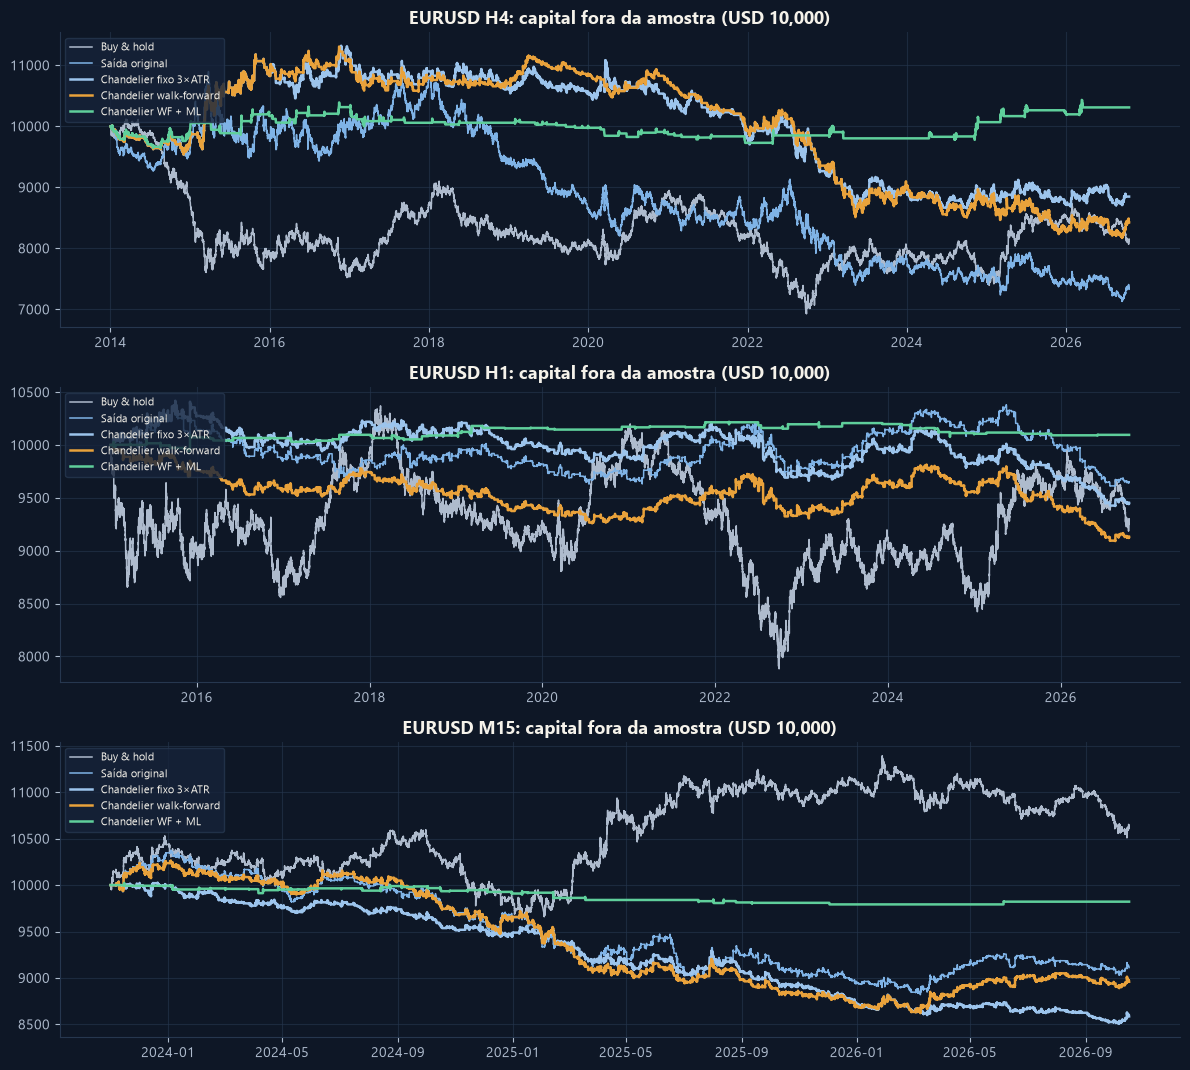

In [10]:
linhas_r = ["Retorno total %", "Retorno sem custos %", "Nº trades", "Win rate %", "Payoff", "Máx. drawdown %", "Sharpe"]
resumo = pd.concat({tf: R["tabela"].loc[linhas_r] for tf, R in RES.items()}, axis=0)
display(resumo.xs("Sharpe", level=1).round(2))

sens_k = pd.DataFrame({tf: R["sharpe_por_k"] for tf, R in RES.items()}).rename_axis("K")
print("Sensibilidade: Sharpe líquido fora da amostra de cada K fixo (diagnóstico, não para escolher K):")
display(sens_k.round(2))

cores_v = [CORES["texto_suave"], CORES["secundaria"], CORES["secundaria_texto"], CORES["primaria"], CORES["positivo"]]
fig, axes = plt.subplots(len(RES), 1, figsize=(12, 3.6 * len(RES)))
for ax, (tf, R) in zip(np.atleast_1d(axes), RES.items()):
    for (nome, c), cor in zip(R["curvas"].items(), cores_v):
        ax.plot(c.index, c.values, color=cor, lw=1.8 if "Chandelier" in nome else 1.1, label=nome)
    ax.set_title(f"{SIMBOLO} {tf}: capital fora da amostra (USD {CAPITAL_INICIAL:,})")
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## 10. Filtro de ML × filtros aleatórios
Para cada timeframe e limiar de probabilidade: quantas operações o filtro aceitou, o retorno total delas e o
**percentil** contra 300 filtros que aceitam o mesmo número de operações **ao acaso**. Acima de 95 é interessante;
perto de 50 é sorte. Um filtro bom deve ficar alto numa **faixa** de limiares, não só em um.

In [11]:
sens_ml = pd.concat({tf: R["sens"] for tf, R in RES.items()}, axis=0).rename_axis(["TF", "limiar"])
sens_ml.round(1)

aceitas  retorno %  percentil
TF  limiar                               
H4  0.4000 214.0000    -2.4000    77.0000
    0.4500 143.0000     0.3000    83.3000
    0.5000  87.0000     3.1000    84.3000
    0.5500  48.0000     9.1000    96.7000
H1  0.4000 337.0000    -8.7000     8.3000
    0.4500 153.0000    -2.3000    42.7000
    0.5000  63.0000     1.0000    82.3000
    0.5500  15.0000     1.3000    92.3000
M15 0.4000 315.0000    -7.2000    14.7000
    0.4500 126.0000    -3.4000    21.0000
    0.5000  38.0000    -1.8000    14.0000
    0.5500   8.0000     0.6000    87.3000

## 11. Salvar os resultados
Pasta `backtests/001.2_sma_chandelier_EURUSD_H4-H1-M15/`: parâmetros, métricas de todas as versões e timeframes,
K escolhido em cada janela, operações fora da amostra com a probabilidade do ML e a sensibilidade.

In [12]:
PASTA_BACKTEST = RAIZ / "backtests" / f"{BACKTEST_ID}_sma_chandelier_{SIMBOLO}_{'-'.join(TIMEFRAMES)}"
PASTA_BACKTEST.mkdir(parents=True, exist_ok=True)
parametros = {
    "id": BACKTEST_ID, "base": "001.1", "simbolo": SIMBOLO, "timeframes": TIMEFRAMES,
    "media_rapida": MEDIA_RAPIDA, "media_lenta": MEDIA_LENTA, "saida": "Chandelier (trailing ATR)",
    "atr_periodo": ATR_PERIODO, "grade_k": GRADE_K, "k_fixo": K_FIXO, "min_trades_treino": MIN_TRADES_TREINO,
    "config_tf": CONFIG_TF, "slippage_pontos": SLIPPAGE_PONTOS, "comissao_pct": COMISSAO_PCT,
    "ml": {"modelo": "regressão logística (C=0.5)", "prob_minima": PROB_MINIMA, "min_trades_ml": MIN_TRADES_ML,
           "auc_oos": {tf: round(float(R["auc"]), 3) for tf, R in RES.items()}},
    "dados_ate": {tf: f"{p['idx'][-1]:%Y-%m-%d}" for tf, p in PREP.items()}, "seed": SEED,
}
(PASTA_BACKTEST / "parametros.json").write_text(json.dumps(parametros, indent=2, ensure_ascii=False), encoding="utf-8")
pd.concat({tf: R["tabela"] for tf, R in RES.items()}).round(4).to_csv(PASTA_BACKTEST / "metricas.csv", encoding="utf-8")
pd.concat({tf: R["wf"] for tf, R in RES.items()}).round(4).to_csv(PASTA_BACKTEST / "walkforward_k.csv", encoding="utf-8")
pd.concat({tf: R["ds_oos"] for tf, R in RES.items()}).round(5).to_csv(PASTA_BACKTEST / "operacoes_oos.csv", encoding="utf-8")
sens_ml.round(2).to_csv(PASTA_BACKTEST / "ml_sensibilidade.csv", encoding="utf-8")
sens_k.round(4).to_csv(PASTA_BACKTEST / "sensibilidade_k.csv", encoding="utf-8")
print(f"Resultados salvos em {PASTA_BACKTEST}")

Resultados salvos em C:\Dev\GitHub\LHS Capital\lhs-quant-lab\backtests\001.2_sma_chandelier_EURUSD_H4-H1-M15


C:\Users\luizh\AppData\Local\Temp\ipykernel_5760\3271699495.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  pd.concat({tf: R["ds_oos"] for tf, R in RES.items()}).round(5).to_csv(PASTA_BACKTEST / "operacoes_oos.csv", encoding="utf-8")


## 12. Conclusões e exercícios

### O que encontramos (rodada de 18/10/2026, EURUSD, só fora da amostra)
| TF | Saída original | Chandelier 3×ATR | Chandelier WF | Chandelier WF + ML | Buy & hold |
|---|---:|---:|---:|---:|---:|
| **H4** (desde 2014) | −26,6% · Sharpe −0,27 | **−11,5% · −0,17** | −15,7% · −0,26 | +3,1% · 0,13 (87 trades) | −18,6% |
| **H1** (desde 2015) | −3,5% · −0,11 | −5,5% · −0,21 | −8,7% · −0,35 | +1,0% · 0,15 (63 trades) | −7,1% |
| **M15** (desde nov/2023) | −8,9% · −0,68 | −14,1% · −1,69 | −10,4% · −0,99 | −1,8% · −0,86 (38 trades) | +6,3% |

**1. O Chandelier ajudou só no H4, e não o suficiente.** Com K = 3, o prejuízo caiu de −26,6% para −11,5% e o drawdown
de −34,6% para −23,6%. É uma melhora real, mas a estratégia continua negativa e empata com o buy & hold.
No H1 e no M15 ele **piorou**: com a regra de zerar no fim do dia, a maioria das operações já termina às 23h, e o stop
só corta as que estavam dando certo.

**2. Otimizar o K não funcionou em nenhum timeframe.** O K escolhido no treino foi pior no teste (H4: Sharpe 0,12 → −0,43)
e o walk-forward ficou **abaixo** do K = 3 fixo nos três timeframes. Mais uma vez, otimizar parâmetros encontrou ruído.

**3. No intraday, o inimigo são os custos.** Sem custos, a saída original ganhava +11,0% no H1 e +7,2% no M15.
Líquido, ficou em −3,5% e −8,9%. São 777 e 841 operações pagando ~1,7 pip cada. O cruzamento 20×50 tem uma
vantagem bruta pequena demais para pagar o spread em gráficos curtos.

**4. O filtro de ML enfraqueceu.** No 001.1, o filtro ficou no percentil 99 contra filtros aleatórios. Aqui, sobre as operações
com Chandelier, ficou em 84 (H4), 82 (H1) e 14 (M15), sempre abaixo de 95, com AUC ≈ 0,53. Isso reforça a suspeita
de que parte do resultado do 001.1 foi sorte.

**Veredito:** ❌ **reprovado.** Uma saída melhor **reduz o prejuízo**, mas não cria vantagem onde a entrada não tem.
A entrada por cruzamento 20×50 está esgotada no EURUSD: já testamos parâmetros, walk-forward, ML e saída.

> Os números acima mudam conforme os dados forem atualizados. Ao rodar de novo, confira as tabelas.

### Lições para o day trade da LHS
- **Primeiro a entrada, depois a saída.** A saída só multiplica uma vantagem que a entrada já tenha.
- **No H1 e no M15, o setup precisa de alvo bruto grande em relação ao spread** (poucas operações por dia, movimentos de vários pips),
  ou o custo come tudo.
- **O próximo setup deve ser intradiário de origem**, pensado para a sessão, como o rompimento da faixa asiática na abertura de Londres,
  e não um setup de tendência adaptado para gráfico curto.

### Exercícios
1. Rode o H1 sem a regra de zerar no fim do dia (`"hora_zerar": 24` e `sessao` com `(0, 24)`). O Chandelier passa a ajudar?
2. Mude `SLIPPAGE_PONTOS` para 0 e veja quanto do prejuízo do M15 é custo.
3. Troque `SIMBOLO` para `"GBPUSD"`, que tem movimentos maiores. A relação com o custo melhora?
4. Experimente `ATR_PERIODO = 50` (stop mais estável). Muda alguma conclusão?